In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load original temporal dataset
df = pd.read_csv("/content/temporal_customer_dataset.csv"

)

# Convert date columns
date_columns = [
    "SnapshotDate",
    "FirstPurchase",
    "LastPurchase",
    "FirstObservedPurchase"
]

for col in date_columns:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col])

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (48079, 18)


In [3]:
print("All Dataset Columns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nFirst 5 Rows:")
display(df.head())

All Dataset Columns:
['CustomerID', 'Monetary', 'TotalQuantity', 'UniqueProducts', 'ActiveDays', 'FirstPurchase', 'LastPurchase', 'Frequency', 'AverageOrderValue', 'WeekendOrderCount', 'AvgDaysBetweenOrders', 'RecencyDays', 'FirstObservedPurchase', 'CustomerTenureDays', 'HasMultipleOrders', 'SnapshotDate', 'FutureOrders90D', 'Churn90D']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48079 entries, 0 to 48078
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   CustomerID             48079 non-null  float64       
 1   Monetary               48079 non-null  float64       
 2   TotalQuantity          48079 non-null  int64         
 3   UniqueProducts         48079 non-null  int64         
 4   ActiveDays             48079 non-null  int64         
 5   FirstPurchase          48079 non-null  datetime64[ns]
 6   LastPurchase           48079 non-null  datetime64[ns]

,CustomerID,Monetary,TotalQuantity,UniqueProducts,ActiveDays,FirstPurchase,LastPurchase,Frequency,AverageOrderValue,WeekendOrderCount,AvgDaysBetweenOrders,RecencyDays,FirstObservedPurchase,CustomerTenureDays,HasMultipleOrders,SnapshotDate,FutureOrders90D,Churn90D
0,12346.0,230.55,51,7,6,2009-12-14 08:34:00,2010-03-02 13:08:00,10,23.0550,0,8.687809,90,2009-12-14 08:34:00,168,1,2010-06-01,1,0
1,12349.0,1268.52,474,47,2,2010-04-29 13:20:00,2010-05-18 09:57:00,2,634.2600,0,18.859028,13,2010-04-29 13:20:00,32,1,2010-06-01,0,1
2,12355.0,488.21,303,22,1,2010-05-21 11:59:00,2010-05-21 11:59:00,1,488.2100,0,NaN,10,2010-05-21 11:59:00,10,0,2010-06-01,0,1
3,12358.0,1429.83,309,17,1,2009-12-08 07:59:00,2009-12-08 07:59:00,1,1429.8300,0,NaN,174,2009-12-08 07:59:00,174,0,2010-06-01,1,0
4,12359.0,1522.23,777,65,4,2009-12-05 13:32:00,2010-03-23 08:55:00,4,380.5575,1,35.935880,69,2009-12-05 13:32:00,177,1,2010-06-01,1,0


In [4]:
print("Total Customers:", df["CustomerID"].nunique())

print(
    "Total Customer Snapshots:",
    len(df)
)

print("\nSnapshot Dates:")
print(sorted(df["SnapshotDate"].dropna().unique()))

print("\nCustomers per Snapshot:")
print(
    df.groupby("SnapshotDate")["CustomerID"]
      .nunique()
)

Total Customers: 5236
Total Customer Snapshots: 48079

Snapshot Dates:
[Timestamp('2010-06-01 00:00:00'), Timestamp('2010-07-01 00:00:00'), Timestamp('2010-08-01 00:00:00'), Timestamp('2010-09-01 00:00:00'), Timestamp('2010-10-01 00:00:00'), Timestamp('2010-11-01 00:00:00'), Timestamp('2010-12-01 00:00:00'), Timestamp('2011-01-01 00:00:00'), Timestamp('2011-02-01 00:00:00'), Timestamp('2011-03-01 00:00:00'), Timestamp('2011-04-01 00:00:00'), Timestamp('2011-05-01 00:00:00'), Timestamp('2011-06-01 00:00:00'), Timestamp('2011-07-01 00:00:00'), Timestamp('2011-08-01 00:00:00'), Timestamp('2011-09-01 00:00:00')]

Customers per Snapshot:
SnapshotDate
2010-06-01    2669
2010-07-01    2757
2010-08-01    2822
2010-09-01    2831
2010-10-01    2910
2010-11-01    3209
2010-12-01    3479
2011-01-01    3415
2011-02-01    3359
2011-03-01    3349
2011-04-01    3304
2011-05-01    3049
2011-06-01    2659
2011-07-01    2724
2011-08-01    2771
2011-09-01    2772
Name: CustomerID, dtype: int64


In [5]:
duplicates = df.duplicated(
    subset=["CustomerID", "SnapshotDate"]
).sum()

print("Duplicate Customer Snapshots:", duplicates)

Duplicate Customer Snapshots: 0


In [6]:
# Create a separate V2 dataset
v2_df = df.copy()

# Sort data chronologically
v2_df = v2_df.sort_values(
    ["CustomerID", "SnapshotDate"]
).reset_index(drop=True)


# Features whose historical values we want to compare
behavior_features = [
    "Monetary",
    "Frequency",
    "TotalQuantity",
    "ActiveDays",
    "AverageOrderValue",
    "RecencyDays"
]


# Function to create historical lag features
def create_lag_features(data, months):

    lagged = data[
        ["CustomerID", "SnapshotDate"] + behavior_features
    ].copy()

    # Move historical snapshot forward to match
    # the corresponding current snapshot
    lagged["SnapshotDate"] = (
        lagged["SnapshotDate"]
        + pd.DateOffset(months=months)
    )

    # Rename historical columns
    rename_dict = {
        col: f"{col}_Prev{months}M"
        for col in behavior_features
    }

    lagged = lagged.rename(columns=rename_dict)

    return lagged


# Previous calendar month
lag1 = create_lag_features(v2_df, 1)

v2_df = v2_df.merge(
    lag1,
    on=["CustomerID", "SnapshotDate"],
    how="left",
    validate="one_to_one"
)


# Three calendar months earlier
lag3 = create_lag_features(v2_df, 3)

v2_df = v2_df.merge(
    lag3,
    on=["CustomerID", "SnapshotDate"],
    how="left",
    validate="one_to_one"
)


print("Historical lag features created!")
print("Updated dataset shape:", v2_df.shape)

Historical lag features created!
Updated dataset shape: (48079, 30)


In [7]:
# Features representing changes from previous month

change_features = [
    "Monetary",
    "Frequency",
    "TotalQuantity",
    "ActiveDays",
    "AverageOrderValue",
    "RecencyDays"
]


for feature in change_features:

    # Absolute monthly change
    v2_df[f"{feature}Change"] = (
        v2_df[feature] -
        v2_df[f"{feature}_Prev1M"]
    )

    # Three-month absolute change
    v2_df[f"{feature}Change3M"] = (
        v2_df[feature] -
        v2_df[f"{feature}_Prev3M"]
    )


print("Absolute behavioural changes created!")

Absolute behavioural changes created!


In [8]:
percentage_features = [
    "Monetary",
    "Frequency",
    "TotalQuantity",
    "ActiveDays",
    "AverageOrderValue"
]


for feature in percentage_features:

    previous = v2_df[f"{feature}_Prev1M"]

    v2_df[f"{feature}PctChange"] = np.where(
        previous > 0,
        (v2_df[feature] - previous) / previous,
        np.nan
    )


print("Percentage change features created!")

Percentage change features created!


In [9]:
v2_df["HasPreviousSnapshot"] = (
    v2_df["Monetary_Prev1M"].notna()
).astype(int)

v2_df["HasThreeMonthHistory"] = (
    v2_df["Monetary_Prev3M"].notna()
).astype(int)


print("Historical availability indicators created!")

Historical availability indicators created!


In [10]:
print("Original dataset shape:", df.shape)
print("V2 dataset shape:", v2_df.shape)

print("\nNew columns:")

new_columns = [
    col for col in v2_df.columns
    if col not in df.columns
]

print(new_columns)
print("\nNumber of new features:", len(new_columns))

Original dataset shape: (48079, 18)
V2 dataset shape: (48079, 49)

New columns:
['Monetary_Prev1M', 'Frequency_Prev1M', 'TotalQuantity_Prev1M', 'ActiveDays_Prev1M', 'AverageOrderValue_Prev1M', 'RecencyDays_Prev1M', 'Monetary_Prev3M', 'Frequency_Prev3M', 'TotalQuantity_Prev3M', 'ActiveDays_Prev3M', 'AverageOrderValue_Prev3M', 'RecencyDays_Prev3M', 'MonetaryChange', 'MonetaryChange3M', 'FrequencyChange', 'FrequencyChange3M', 'TotalQuantityChange', 'TotalQuantityChange3M', 'ActiveDaysChange', 'ActiveDaysChange3M', 'AverageOrderValueChange', 'AverageOrderValueChange3M', 'RecencyDaysChange', 'RecencyDaysChange3M', 'MonetaryPctChange', 'FrequencyPctChange', 'TotalQuantityPctChange', 'ActiveDaysPctChange', 'AverageOrderValuePctChange', 'HasPreviousSnapshot', 'HasThreeMonthHistory']

Number of new features: 31


In [11]:
new_feature_missing = (
    v2_df[new_columns]
    .isnull()
    .sum()
    .sort_values(ascending=False)
)

print("Missing values in new features:")
print(new_feature_missing)

Missing values in new features:
Monetary_Prev3M               16818
MonetaryChange3M              16818
RecencyDays_Prev3M            16818
AverageOrderValue_Prev3M      16818
ActiveDays_Prev3M             16818
TotalQuantity_Prev3M          16818
Frequency_Prev3M              16818
ActiveDaysChange3M            16818
AverageOrderValueChange3M     16818
TotalQuantityChange3M         16818
RecencyDaysChange3M           16818
FrequencyChange3M             16818
RecencyDays_Prev1M             6277
ActiveDays_Prev1M              6277
AverageOrderValue_Prev1M       6277
FrequencyChange                6277
MonetaryChange                 6277
Frequency_Prev1M               6277
Monetary_Prev1M                6277
TotalQuantity_Prev1M           6277
ActiveDaysChange               6277
AverageOrderValueChange        6277
TotalQuantityChange            6277
RecencyDaysChange              6277
MonetaryPctChange              6277
FrequencyPctChange             6277
TotalQuantityPctChange         6

In [12]:
display(
    v2_df[
        [
            "CustomerID",
            "SnapshotDate",
            "Monetary",
            "Monetary_Prev1M",
            "MonetaryChange",
            "MonetaryPctChange",
            "Frequency",
            "Frequency_Prev1M",
            "FrequencyChange",
            "RecencyDays",
            "RecencyDays_Prev1M",
            "RecencyDaysChange"
        ]
    ].head(15)
)

,CustomerID,SnapshotDate,Monetary,Monetary_Prev1M,MonetaryChange,MonetaryPctChange,Frequency,Frequency_Prev1M,FrequencyChange,RecencyDays,RecencyDays_Prev1M,RecencyDaysChange
0,12346.0,2010-06-01,230.55,NaN,NaN,NaN,10,NaN,NaN,90,NaN,NaN
1,12346.0,2010-07-01,259.36,230.55,28.81,0.124962,6,10.0,-4.0,2,90.0,-88.0
2,12346.0,2010-08-01,169.36,259.36,-90.00,-0.347008,2,6.0,-4.0,33,2.0,31.0
3,12346.0,2010-09-01,142.31,169.36,-27.05,-0.159719,1,2.0,-1.0,64,33.0,31.0
4,12346.0,2010-10-01,142.31,142.31,0.00,0.000000,1,1.0,0.0,94,64.0,30.0
5,12346.0,2010-11-01,142.31,142.31,0.00,0.000000,1,1.0,0.0,125,94.0,31.0
6,12346.0,2010-12-01,142.31,142.31,0.00,0.000000,1,1.0,0.0,155,125.0,30.0
7,12346.0,2011-02-01,77183.60,NaN,NaN,NaN,1,NaN,NaN,13,NaN,NaN
8,12346.0,2011-03-01,77183.60,77183.60,0.00,0.000000,1,1.0,0.0,41,13.0,28.0
9,12346.0,2011-04-01,77183.60,77183.60,0.00,0.000000,1,1.0,0.0,72,41.0,31.0


In [13]:
assert len(v2_df) == len(df)

assert not v2_df.duplicated(
    subset=["CustomerID", "SnapshotDate"]
).any()

print("Row count preserved.")
print("No duplicate customer snapshots.")

Row count preserved.
No duplicate customer snapshots.


In [14]:
print("Original columns:", len(df.columns))
print("V2 columns:", len(v2_df.columns))

print("New feature count:", len(new_columns))

print("\nDuplicate column names:")
print(v2_df.columns[v2_df.columns.duplicated()].tolist())

print("\nAll V2 columns:")
print(v2_df.columns.tolist())

Original columns: 18
V2 columns: 49
New feature count: 31

Duplicate column names:
[]

All V2 columns:
['CustomerID', 'Monetary', 'TotalQuantity', 'UniqueProducts', 'ActiveDays', 'FirstPurchase', 'LastPurchase', 'Frequency', 'AverageOrderValue', 'WeekendOrderCount', 'AvgDaysBetweenOrders', 'RecencyDays', 'FirstObservedPurchase', 'CustomerTenureDays', 'HasMultipleOrders', 'SnapshotDate', 'FutureOrders90D', 'Churn90D', 'Monetary_Prev1M', 'Frequency_Prev1M', 'TotalQuantity_Prev1M', 'ActiveDays_Prev1M', 'AverageOrderValue_Prev1M', 'RecencyDays_Prev1M', 'Monetary_Prev3M', 'Frequency_Prev3M', 'TotalQuantity_Prev3M', 'ActiveDays_Prev3M', 'AverageOrderValue_Prev3M', 'RecencyDays_Prev3M', 'MonetaryChange', 'MonetaryChange3M', 'FrequencyChange', 'FrequencyChange3M', 'TotalQuantityChange', 'TotalQuantityChange3M', 'ActiveDaysChange', 'ActiveDaysChange3M', 'AverageOrderValueChange', 'AverageOrderValueChange3M', 'RecencyDaysChange', 'RecencyDaysChange3M', 'MonetaryPctChange', 'FrequencyPctChange', 

In [15]:
customer_id = 12346.0

check_customer = (
    v2_df[v2_df["CustomerID"] == customer_id]
    .sort_values("SnapshotDate")
)

display(
    check_customer[
        [
            "CustomerID",
            "SnapshotDate",
            "Monetary",
            "Monetary_Prev1M",
            "Monetary_Prev3M",
            "MonetaryChange",
            "MonetaryChange3M",
            "HasPreviousSnapshot",
            "HasThreeMonthHistory"
        ]
    ]
)

,CustomerID,SnapshotDate,Monetary,Monetary_Prev1M,Monetary_Prev3M,MonetaryChange,MonetaryChange3M,HasPreviousSnapshot,HasThreeMonthHistory
0,12346.0,2010-06-01,230.55,NaN,NaN,NaN,NaN,0,0
1,12346.0,2010-07-01,259.36,230.55,NaN,28.81,NaN,1,0
2,12346.0,2010-08-01,169.36,259.36,NaN,-90.00,NaN,1,0
3,12346.0,2010-09-01,142.31,169.36,230.55,-27.05,-88.24,1,1
4,12346.0,2010-10-01,142.31,142.31,259.36,0.00,-117.05,1,1
5,12346.0,2010-11-01,142.31,142.31,169.36,0.00,-27.05,1,1
6,12346.0,2010-12-01,142.31,142.31,142.31,0.00,0.00,1,1
7,12346.0,2011-02-01,77183.60,NaN,142.31,NaN,77041.29,0,1
8,12346.0,2011-03-01,77183.60,77183.60,142.31,0.00,77041.29,1,1
9,12346.0,2011-04-01,77183.60,77183.60,NaN,0.00,NaN,1,0


In [16]:
# Target variable
target = "Churn90D"

# Columns that must not be used as predictors
excluded_columns = [
    "CustomerID",
    "SnapshotDate",
    "FirstPurchase",
    "LastPurchase",
    "FirstObservedPurchase",
    "FutureOrders90D",
    "Churn90D"
]

# Select numeric feature columns
feature_columns_v2 = [
    col for col in v2_df.select_dtypes(include=np.number).columns
    if col not in excluded_columns
]

print("Total V2 features:", len(feature_columns_v2))

print("\nV2 Features:")
print(feature_columns_v2)

Total V2 features: 42

V2 Features:
['Monetary', 'TotalQuantity', 'UniqueProducts', 'ActiveDays', 'Frequency', 'AverageOrderValue', 'WeekendOrderCount', 'AvgDaysBetweenOrders', 'RecencyDays', 'CustomerTenureDays', 'HasMultipleOrders', 'Monetary_Prev1M', 'Frequency_Prev1M', 'TotalQuantity_Prev1M', 'ActiveDays_Prev1M', 'AverageOrderValue_Prev1M', 'RecencyDays_Prev1M', 'Monetary_Prev3M', 'Frequency_Prev3M', 'TotalQuantity_Prev3M', 'ActiveDays_Prev3M', 'AverageOrderValue_Prev3M', 'RecencyDays_Prev3M', 'MonetaryChange', 'MonetaryChange3M', 'FrequencyChange', 'FrequencyChange3M', 'TotalQuantityChange', 'TotalQuantityChange3M', 'ActiveDaysChange', 'ActiveDaysChange3M', 'AverageOrderValueChange', 'AverageOrderValueChange3M', 'RecencyDaysChange', 'RecencyDaysChange3M', 'MonetaryPctChange', 'FrequencyPctChange', 'TotalQuantityPctChange', 'ActiveDaysPctChange', 'AverageOrderValuePctChange', 'HasPreviousSnapshot', 'HasThreeMonthHistory']


In [17]:
# Training period
train_mask_v2 = (
    v2_df["SnapshotDate"] <= "2010-10-01"
)

# Validation period
val_mask_v2 = (
    (v2_df["SnapshotDate"] >= "2011-02-01") &
    (v2_df["SnapshotDate"] <= "2011-05-01")
)

# Testing period
test_mask_v2 = (
    v2_df["SnapshotDate"] == "2011-09-01"
)


# Create feature datasets
X_train_v2 = v2_df.loc[
    train_mask_v2, feature_columns_v2
]

X_val_v2 = v2_df.loc[
    val_mask_v2, feature_columns_v2
]

X_test_v2 = v2_df.loc[
    test_mask_v2, feature_columns_v2
]


# Create target datasets
y_train_v2 = v2_df.loc[train_mask_v2, target]

y_val_v2 = v2_df.loc[val_mask_v2, target]

y_test_v2 = v2_df.loc[test_mask_v2, target]


print("Training Shape:", X_train_v2.shape)
print("Validation Shape:", X_val_v2.shape)
print("Testing Shape:", X_test_v2.shape)

Training Shape: (13989, 42)
Validation Shape: (13061, 42)
Testing Shape: (2772, 42)


In [18]:
print("TRAINING CHURN DISTRIBUTION")
print(y_train_v2.value_counts(normalize=True) * 100)

print("\nVALIDATION CHURN DISTRIBUTION")
print(y_val_v2.value_counts(normalize=True) * 100)

print("\nTESTING CHURN DISTRIBUTION")
print(y_test_v2.value_counts(normalize=True) * 100)

TRAINING CHURN DISTRIBUTION
Churn90D
0    55.565087
1    44.434913
Name: proportion, dtype: float64

VALIDATION CHURN DISTRIBUTION
Churn90D
1    56.66488
0    43.33512
Name: proportion, dtype: float64

TESTING CHURN DISTRIBUTION
Churn90D
0    60.714286
1    39.285714
Name: proportion, dtype: float64


In [19]:
print("Missing values in training:")
display(
    X_train_v2.isnull().sum()
    .sort_values(ascending=False)
    .head(15)
)

print("\nMissing values in validation:")
display(
    X_val_v2.isnull().sum()
    .sort_values(ascending=False)
    .head(15)
)

print("\nMissing values in testing:")
display(
    X_test_v2.isnull().sum()
    .sort_values(ascending=False)
    .head(15)
)

Missing values in training:


,0
AverageOrderValueChange3M,9514
ActiveDaysChange3M,9514
FrequencyChange3M,9514
TotalQuantity_Prev3M,9514
Frequency_Prev3M,9514
AverageOrderValue_Prev3M,9514
RecencyDays_Prev3M,9514
MonetaryChange3M,9514
ActiveDays_Prev3M,9514
Monetary_Prev3M,9514



Missing values in validation:


,0
AvgDaysBetweenOrders,6015
ActiveDaysChange3M,2032
FrequencyChange3M,2032
TotalQuantity_Prev3M,2032
Frequency_Prev3M,2032
AverageOrderValue_Prev3M,2032
RecencyDays_Prev3M,2032
MonetaryChange3M,2032
ActiveDays_Prev3M,2032
Monetary_Prev3M,2032



Missing values in testing:


,0
AvgDaysBetweenOrders,1278
ActiveDaysChange3M,608
FrequencyChange3M,608
TotalQuantity_Prev3M,608
Frequency_Prev3M,608
AverageOrderValue_Prev3M,608
RecencyDays_Prev3M,608
MonetaryChange3M,608
ActiveDays_Prev3M,608
Monetary_Prev3M,608


In [20]:
# Check forbidden columns
forbidden_features = [
    "CustomerID",
    "SnapshotDate",
    "FirstPurchase",
    "LastPurchase",
    "FirstObservedPurchase",
    "FutureOrders90D",
    "Churn90D"
]

leakage_columns = [
    col for col in feature_columns_v2
    if col in forbidden_features
]

print("Forbidden columns included:", leakage_columns)

assert len(leakage_columns) == 0

# Check shapes and row alignment
assert len(X_train_v2) == len(y_train_v2)
assert len(X_val_v2) == len(y_val_v2)
assert len(X_test_v2) == len(y_test_v2)

print("Feature and target alignment verified!")

Forbidden columns included: []
Feature and target alignment verified!


In [21]:
import os

output_path = (
    "/content/drive/MyDrive/"
    "Customer-Lifecycle-Intelligence/data/processed/"
)

os.makedirs(output_path, exist_ok=True)

v2_df.to_csv(
    output_path + "temporal_customer_dataset_v2.csv",
    index=False
)

print("V2 temporal dataset saved successfully!")

V2 temporal dataset saved successfully!


In [22]:
!pip install xgboost -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import joblib
import os

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [23]:
# Logistic Regression Pipeline
logistic_v2 = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=3000,
        random_state=42
    ))
])


# Random Forest Pipeline
rf_v2 = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("model", RandomForestClassifier(
        n_estimators=400,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=3,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ))
])


# XGBoost Pipeline
xgb_v2 = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("model", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.5,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])


models_v2 = {
    "Logistic Regression V2": logistic_v2,
    "Random Forest V2": rf_v2,
    "XGBoost V2": xgb_v2
}

print("All V2 model pipelines created!")

All V2 model pipelines created!


In [24]:
trained_models_v2 = {}

for name, model in models_v2.items():

    print(f"\nTraining {name}...")

    model.fit(
        X_train_v2,
        y_train_v2
    )

    trained_models_v2[name] = model

    print(f"{name} trained successfully!")

print("\nAll V2 models have been trained!")


Training Logistic Regression V2...
Logistic Regression V2 trained successfully!

Training Random Forest V2...
Random Forest V2 trained successfully!

Training XGBoost V2...
XGBoost V2 trained successfully!

All V2 models have been trained!


In [25]:
validation_results_v2 = []

for name, model in trained_models_v2.items():

    # Predict churn probabilities
    y_prob = model.predict_proba(X_val_v2)[:, 1]

    # Apply threshold 0.50
    y_pred = (y_prob >= 0.50).astype(int)

    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_val_v2, y_pred),
        "Precision": precision_score(y_val_v2, y_pred, zero_division=0),
        "Recall": recall_score(y_val_v2, y_pred, zero_division=0),
        "F1 Score": f1_score(y_val_v2, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val_v2, y_prob),
        "PR-AUC": average_precision_score(y_val_v2, y_prob),
        "Balanced Accuracy": balanced_accuracy_score(y_val_v2, y_pred)
    }

    validation_results_v2.append(results)


results_v2_df = pd.DataFrame(validation_results_v2)

display(
    results_v2_df.round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Balanced Accuracy
0,Logistic Regression V2,0.5925,0.7978,0.3763,0.5114,0.7500,0.7592,0.6258
1,Random Forest V2,0.6223,0.7906,0.4536,0.5765,0.7529,0.7607,0.6483
2,XGBoost V2,0.5986,0.7918,0.3956,0.5276,0.7504,0.7612,0.6298


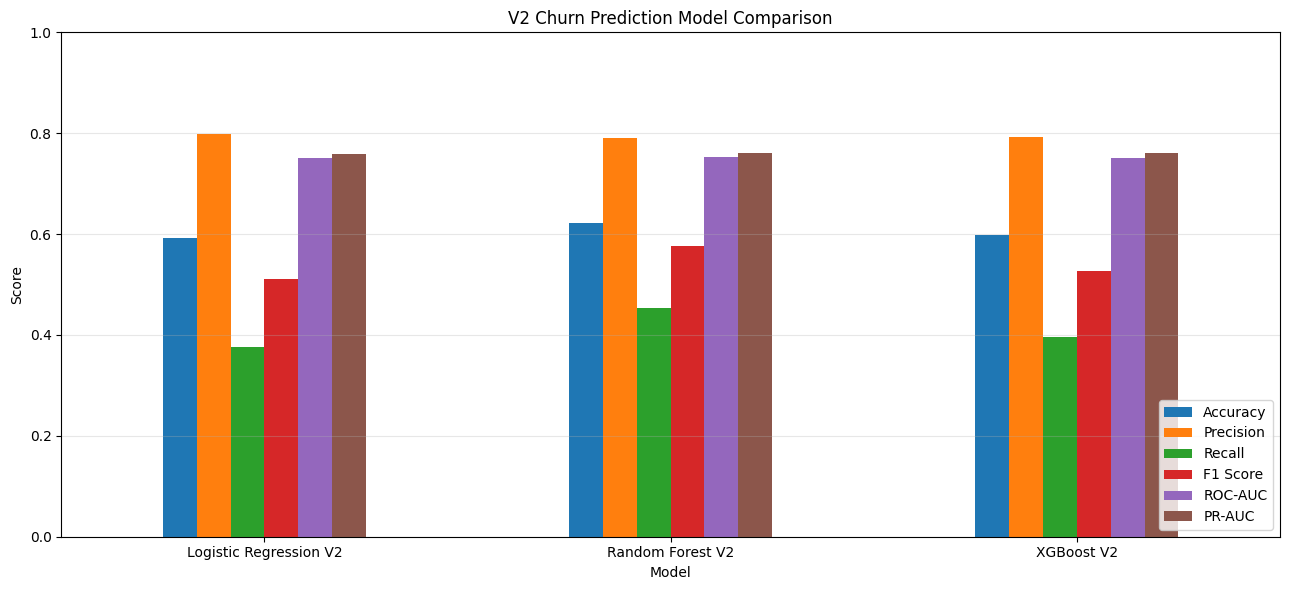

In [26]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC",
    "PR-AUC"
]

results_plot = results_v2_df.set_index("Model")[metrics]

results_plot.plot(
    kind="bar",
    figsize=(13, 6),
    ylim=(0, 1)
)

plt.title("V2 Churn Prediction Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
# Get churn probabilities on validation data
rf_v2_prob = trained_models_v2[
    "Random Forest V2"
].predict_proba(X_val_v2)[:, 1]

print("Validation probabilities generated!")
print("Number of predictions:", len(rf_v2_prob))

Validation probabilities generated!
Number of predictions: 13061


In [28]:
threshold_results_v2 = []

thresholds = np.arange(0.10, 0.61, 0.01)

for threshold in thresholds:

    predictions = (
        rf_v2_prob >= threshold
    ).astype(int)

    precision = precision_score(
        y_val_v2, predictions, zero_division=0
    )

    recall = recall_score(
        y_val_v2, predictions, zero_division=0
    )

    f1 = f1_score(
        y_val_v2, predictions, zero_division=0
    )

    predicted_churn_rate = predictions.mean()

    threshold_results_v2.append({
        "Threshold": round(threshold, 2),
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Predicted Churn Rate": predicted_churn_rate
    })


threshold_df_v2 = pd.DataFrame(
    threshold_results_v2
)

display(
    threshold_df_v2.sort_values(
        "F1 Score",
        ascending=False
    ).head(15).round(4)
)

,Threshold,Precision,Recall,F1 Score,Predicted Churn Rate
11,0.21,0.6612,0.9314,0.7734,0.7982
10,0.20,0.6572,0.9392,0.7733,0.8098
9,0.19,0.6530,0.9455,0.7725,0.8205
12,0.22,0.6645,0.9224,0.7725,0.7866
14,0.24,0.6722,0.9050,0.7714,0.7629
8,0.18,0.6487,0.9507,0.7712,0.8305
15,0.25,0.6769,0.8958,0.7711,0.7499
13,0.23,0.6677,0.9122,0.7710,0.7741
16,0.26,0.6817,0.8839,0.7698,0.7347
7,0.17,0.6441,0.9558,0.7696,0.8408


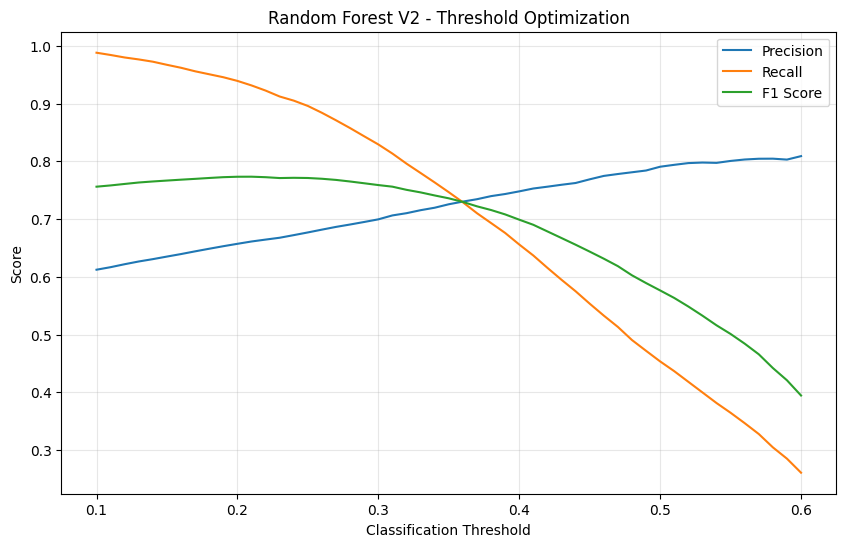

In [29]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df_v2["Threshold"],
    threshold_df_v2["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df_v2["Threshold"],
    threshold_df_v2["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df_v2["Threshold"],
    threshold_df_v2["F1 Score"],
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Random Forest V2 - Threshold Optimization")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [30]:
# Evaluate selected thresholds
selected_thresholds = [
    0.21, 0.25, 0.30, 0.32,
    0.34, 0.35, 0.36, 0.38, 0.40
]

threshold_comparison = []

for threshold in selected_thresholds:

    predictions = (
        rf_v2_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_v2,
        predictions,
        labels=[0, 1]
    ).ravel()

    threshold_comparison.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val_v2, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val_v2, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val_v2, predictions, zero_division=0
        ),
        "Specificity": tn / (tn + fp),
        "Balanced Accuracy": (tp / (tp + fn) + tn / (tn + fp)) / 2,
        "Predicted Churn Rate": predictions.mean()
    })

threshold_comparison_df = pd.DataFrame(
    threshold_comparison
)

display(threshold_comparison_df.round(4))

,Threshold,Precision,Recall,F1,Specificity,Balanced Accuracy,Predicted Churn Rate
0,0.21,0.6612,0.9314,0.7734,0.3760,0.6537,0.7982
1,0.25,0.6769,0.8958,0.7711,0.4408,0.6683,0.7499
2,0.30,0.6995,0.8292,0.7589,0.5343,0.6817,0.6717
3,0.32,0.7102,0.7960,0.7506,0.5753,0.6856,0.6351
4,0.34,0.7197,0.7634,0.7409,0.6111,0.6873,0.6011
5,0.35,0.7256,0.7465,0.7359,0.6309,0.6887,0.5830
6,0.36,0.7303,0.7291,0.7297,0.6479,0.6885,0.5657
7,0.38,0.7397,0.6931,0.7157,0.6811,0.6871,0.5310
8,0.40,0.7480,0.6560,0.6990,0.7110,0.6835,0.4970


In [31]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance on validation data
rf_permutation = permutation_importance(
    trained_models_v2["Random Forest V2"],
    X_val_v2,
    y_val_v2,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Create feature importance dataframe
feature_importance_v2 = pd.DataFrame({
    "Feature": X_val_v2.columns,
    "Importance": rf_permutation.importances_mean,
    "Std": rf_permutation.importances_std
})

# Sort by importance
feature_importance_v2 = feature_importance_v2.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance_v2.head(20).round(5))

,Feature,Importance,Std
9,CustomerTenureDays,0.01229,0.00225
8,RecencyDays,0.00569,0.00030
2,UniqueProducts,0.00530,0.00141
0,Monetary,0.00484,0.00204
16,RecencyDays_Prev1M,0.00124,0.00031
3,ActiveDays,0.00119,0.00211
28,TotalQuantityChange3M,0.00054,0.00091
23,MonetaryChange,0.00028,0.00038
5,AverageOrderValue,0.00027,0.00097
7,AvgDaysBetweenOrders,0.00023,0.00199


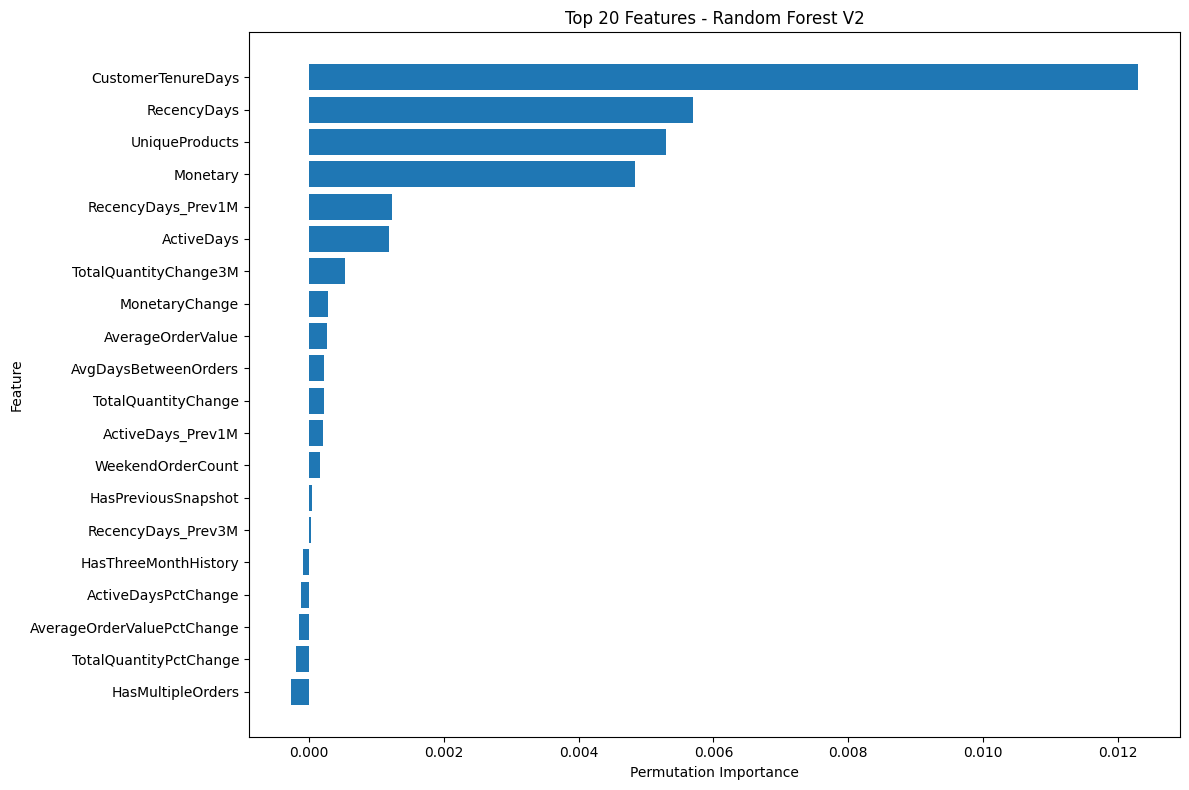

In [32]:
top_features = feature_importance_v2.head(20)

plt.figure(figsize=(12, 8))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Permutation Importance")
plt.ylabel("Feature")
plt.title("Top 20 Features - Random Forest V2")

plt.tight_layout()
plt.show()

In [33]:
original_features = [
    "Monetary",
    "TotalQuantity",
    "UniqueProducts",
    "ActiveDays",
    "Frequency",
    "AverageOrderValue",
    "WeekendOrderCount",
    "AvgDaysBetweenOrders",
    "RecencyDays",
    "CustomerTenureDays",
    "HasMultipleOrders"
]

feature_importance_v2["Feature_Type"] = (
    feature_importance_v2["Feature"].apply(
        lambda x: "Original"
        if x in original_features
        else "Engineered"
    )
)

importance_summary = (
    feature_importance_v2
    .groupby("Feature_Type")["Importance"]
    .agg(["mean", "median", "sum", "count"])
)

display(importance_summary.round(5))

,mean,median,sum,count
Feature_Type,,,,
Engineered,-0.00040,-0.00044,-0.01249,31
Original,0.00259,0.00027,0.02847,11


In [34]:
original_features = [
    "Monetary",
    "TotalQuantity",
    "UniqueProducts",
    "ActiveDays",
    "Frequency",
    "AverageOrderValue",
    "WeekendOrderCount",
    "AvgDaysBetweenOrders",
    "RecencyDays",
    "CustomerTenureDays",
    "HasMultipleOrders"
]

# All 42 features
all_features = feature_columns_v2

print("Original features:", len(original_features))
print("All features:", len(all_features))

Original features: 11
All features: 42


In [35]:
rf_original = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),

    ("model", RandomForestClassifier(
        n_estimators=400,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=3,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ))
])

# Train using original features only
rf_original.fit(
    X_train_v2[original_features],
    y_train_v2
)

print("Original-feature model trained!")

Original-feature model trained!


In [36]:
rf_original = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),

    ("model", RandomForestClassifier(
        n_estimators=400,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=3,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ))
])

# Train using original features only
rf_original.fit(
    X_train_v2[original_features],
    y_train_v2
)

print("Original-feature model trained!")

Original-feature model trained!


In [37]:
# Original model probabilities
original_prob = rf_original.predict_proba(
    X_val_v2[original_features]
)[:, 1]

# V2 model probabilities
v2_prob = trained_models_v2[
    "Random Forest V2"
].predict_proba(X_val_v2)[:, 1]


# Use the same threshold for both
threshold = 0.50

original_pred = (
    original_prob >= threshold
).astype(int)

v2_pred = (
    v2_prob >= threshold
).astype(int)


# Evaluation function
def evaluate_model(name, y_true, predictions, probabilities):

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(
            y_true, probabilities
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true, predictions
        )
    }


ablation_results = []

ablation_results.append(
    evaluate_model(
        "Original Features - 11",
        y_val_v2,
        original_pred,
        original_prob
    )
)

ablation_results.append(
    evaluate_model(
        "All Features - 42",
        y_val_v2,
        v2_pred,
        v2_prob
    )
)

ablation_df = pd.DataFrame(ablation_results)

display(ablation_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Balanced Accuracy
0,Original Features - 11,0.6036,0.7912,0.4081,0.5384,0.7494,0.7608,0.6336
1,All Features - 42,0.6223,0.7906,0.4536,0.5765,0.7529,0.7607,0.6483


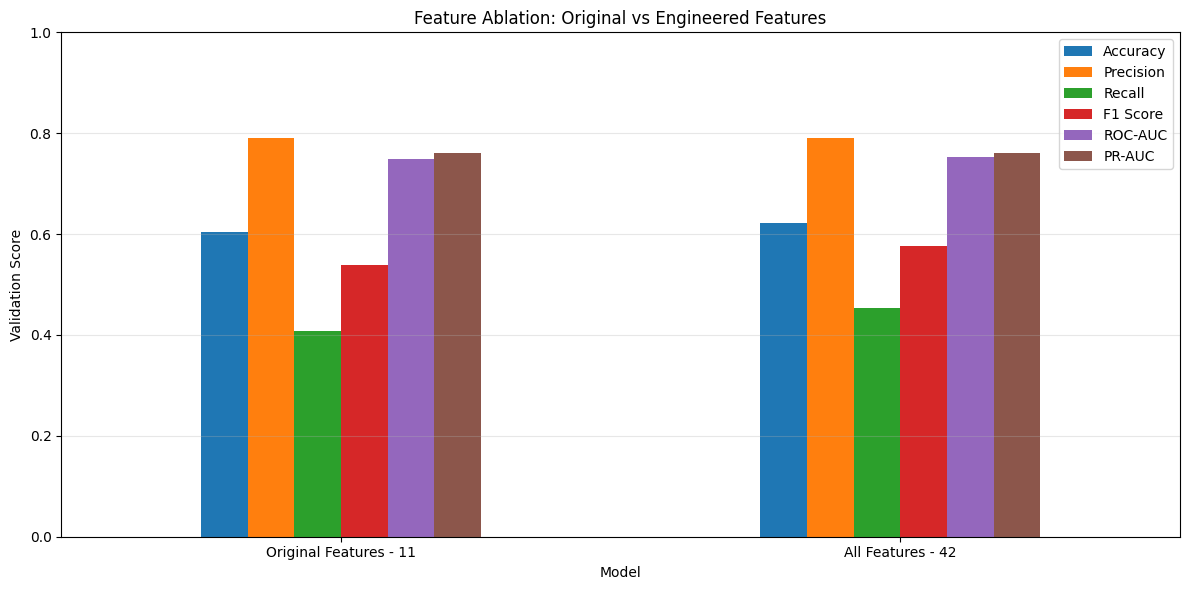

In [38]:
comparison_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC",
    "PR-AUC"
]

ablation_plot = ablation_df.set_index(
    "Model"
)[comparison_metrics]

ablation_plot.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1)
)

plt.title("Feature Ablation: Original vs Engineered Features")
plt.ylabel("Validation Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [39]:
rf_configs = [
    {
        "n_estimators": 300,
        "max_depth": 8,
        "min_samples_split": 10,
        "min_samples_leaf": 5,
        "max_features": "sqrt"
    },
    {
        "n_estimators": 400,
        "max_depth": 12,
        "min_samples_split": 10,
        "min_samples_leaf": 3,
        "max_features": "sqrt"
    },
    {
        "n_estimators": 500,
        "max_depth": 16,
        "min_samples_split": 10,
        "min_samples_leaf": 3,
        "max_features": "sqrt"
    },
    {
        "n_estimators": 400,
        "max_depth": 12,
        "min_samples_split": 20,
        "min_samples_leaf": 5,
        "max_features": 0.7
    },
    {
        "n_estimators": 500,
        "max_depth": 16,
        "min_samples_split": 20,
        "min_samples_leaf": 5,
        "max_features": 0.7
    }
]

print("Number of configurations:", len(rf_configs))

Number of configurations: 5


In [40]:
tuning_results = []
tuned_rf_models = {}

for i, params in enumerate(rf_configs):

    print(f"\nTraining configuration {i + 1}/5")

    model = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            add_indicator=True
        )),

        ("model", RandomForestClassifier(
            **params,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train_v2, y_train_v2)

    probabilities = model.predict_proba(X_val_v2)[:, 1]

    predictions = (
        probabilities >= 0.50
    ).astype(int)

    result = {
        "Configuration": i + 1,
        "Accuracy": accuracy_score(y_val_v2, predictions),
        "Precision": precision_score(
            y_val_v2, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val_v2, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val_v2, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val_v2, probabilities),
        "PR-AUC": average_precision_score(
            y_val_v2, probabilities
        )
    }

    tuning_results.append(result)
    tuned_rf_models[i + 1] = model

tuning_df = pd.DataFrame(tuning_results)

display(
    tuning_df.sort_values(
        "PR-AUC",
        ascending=False
    ).round(4)
)


Training configuration 1/5

Training configuration 2/5

Training configuration 3/5

Training configuration 4/5

Training configuration 5/5


,Configuration,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,1,0.6365,0.7925,0.4856,0.6022,0.7606,0.7661
1,2,0.6223,0.7906,0.4536,0.5765,0.7529,0.7607
2,3,0.6155,0.7857,0.4420,0.5657,0.7475,0.7558
3,4,0.6018,0.7901,0.4048,0.5353,0.7432,0.7544
4,5,0.5908,0.7841,0.3833,0.5149,0.7376,0.7491


In [41]:
# Best tuned Random Forest
best_rf = tuned_rf_models[1]

# Existing models
xgb_model = trained_models_v2["XGBoost V2"]
lr_model = trained_models_v2["Logistic Regression V2"]


# Generate probabilities
rf_prob = best_rf.predict_proba(X_val_v2)[:, 1]

xgb_prob = xgb_model.predict_proba(X_val_v2)[:, 1]

lr_prob = lr_model.predict_proba(X_val_v2)[:, 1]


# Classification threshold
threshold = 0.50

rf_pred = (rf_prob >= threshold).astype(int)
xgb_pred = (xgb_prob >= threshold).astype(int)
lr_pred = (lr_prob >= threshold).astype(int)

In [42]:
models_to_compare = {
    "Tuned Random Forest": (rf_pred, rf_prob),
    "XGBoost V2": (xgb_pred, xgb_prob),
    "Logistic Regression V2": (lr_pred, lr_prob)
}

comparison_results = []

for name, (pred, prob) in models_to_compare.items():

    comparison_results.append({
        "Model": name,

        "Accuracy": accuracy_score(y_val_v2, pred),

        "Precision": precision_score(
            y_val_v2, pred, zero_division=0
        ),

        "Recall": recall_score(
            y_val_v2, pred, zero_division=0
        ),

        "F1 Score": f1_score(
            y_val_v2, pred, zero_division=0
        ),

        "ROC-AUC": roc_auc_score(y_val_v2, prob),

        "PR-AUC": average_precision_score(
            y_val_v2, prob
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_val_v2, pred
        )
    })


final_comparison = pd.DataFrame(comparison_results)

display(
    final_comparison.sort_values(
        "PR-AUC",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Balanced Accuracy
0,Tuned Random Forest,0.6365,0.7925,0.4856,0.6022,0.7606,0.7661,0.6597
1,XGBoost V2,0.5986,0.7918,0.3956,0.5276,0.7504,0.7612,0.6298
2,Logistic Regression V2,0.5925,0.7978,0.3763,0.5114,0.7500,0.7592,0.6258


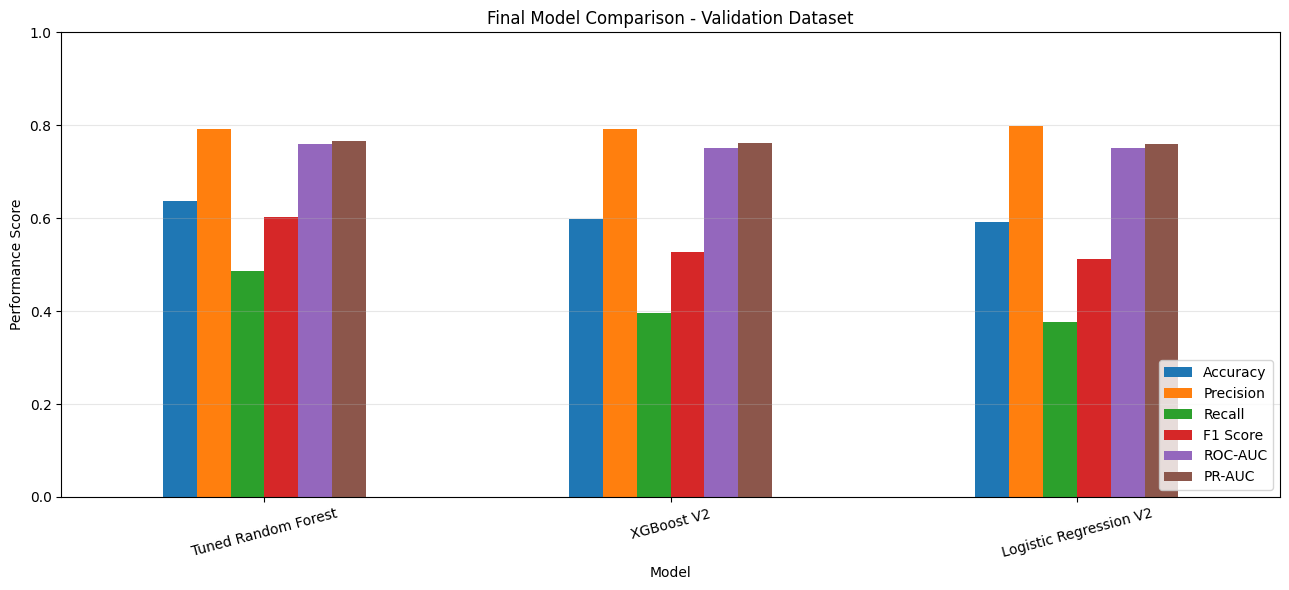

In [43]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC",
    "PR-AUC"
]

final_comparison.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(13, 6),
    ylim=(0, 1)
)

plt.title("Final Model Comparison - Validation Dataset")
plt.ylabel("Performance Score")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [44]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix
)

# Probabilities from the best tuned Random Forest
best_rf = tuned_rf_models[1]

val_probabilities = best_rf.predict_proba(
    X_val_v2
)[:, 1]

threshold_results = []

thresholds = np.arange(0.10, 0.71, 0.01)

for threshold in thresholds:

    predictions = (
        val_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_v2,
        predictions,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_val_v2,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_val_v2,
        predictions,
        zero_division=0
    )

    specificity = tn / (tn + fp)

    f1 = f1_score(
        y_val_v2,
        predictions,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Specificity": specificity,
        "Balanced Accuracy": (recall + specificity) / 2,
        "Predicted Churn Rate": predictions.mean()
    })


threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.sort_values(
        "F1 Score",
        ascending=False
    ).head(15).round(4)
)

,Threshold,Precision,Recall,F1 Score,Specificity,Balanced Accuracy,Predicted Churn Rate
13,0.23,0.6703,0.9256,0.7775,0.4048,0.6652,0.7824
11,0.21,0.6629,0.9397,0.7774,0.3753,0.6575,0.8032
12,0.22,0.6665,0.9320,0.7772,0.3901,0.6611,0.7924
10,0.20,0.6589,0.9470,0.7771,0.3588,0.6529,0.8145
14,0.24,0.6723,0.9154,0.7753,0.4166,0.6660,0.7715
9,0.19,0.6539,0.9514,0.7751,0.3415,0.6464,0.8244
15,0.25,0.6764,0.9073,0.7750,0.4325,0.6699,0.7600
16,0.26,0.6812,0.8977,0.7746,0.4507,0.6742,0.7467
17,0.27,0.6862,0.8888,0.7745,0.4686,0.6787,0.7339
8,0.18,0.6490,0.9578,0.7737,0.3226,0.6402,0.8363


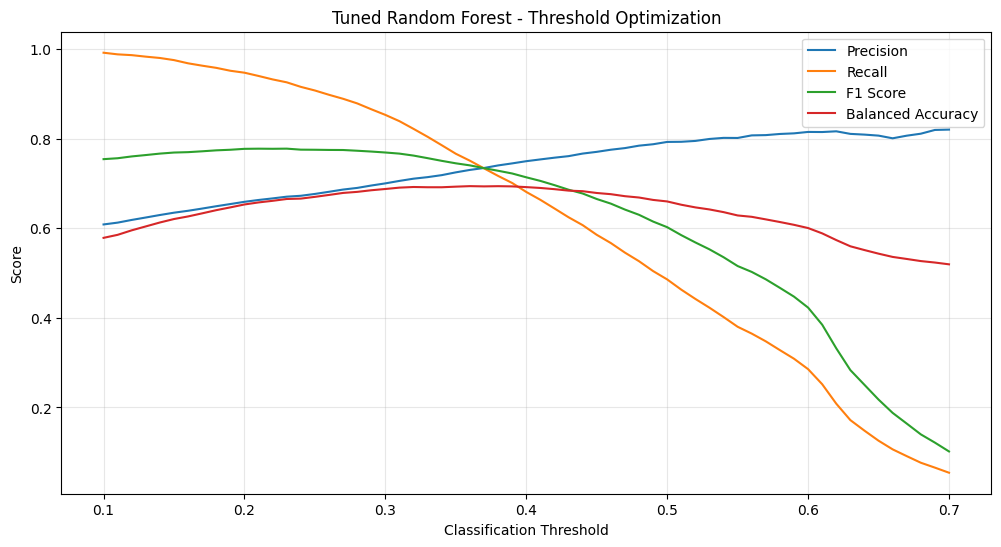

In [45]:
plt.figure(figsize=(12, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    label="F1 Score"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Balanced Accuracy"],
    label="Balanced Accuracy"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Tuned Random Forest - Threshold Optimization")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [46]:
# Best threshold according to balanced accuracy
best_balanced = threshold_df.loc[
    threshold_df["Balanced Accuracy"].idxmax()
]

print("BEST BALANCED ACCURACY THRESHOLD")
display(best_balanced.to_frame().round(4))


# Examine thresholds from 0.30 to 0.50
middle_thresholds = threshold_df[
    (threshold_df["Threshold"] >= 0.30) &
    (threshold_df["Threshold"] <= 0.50)
]

display(
    middle_thresholds.round(4)
)


# Compare the three selection strategies
best_f1 = threshold_df.loc[
    threshold_df["F1 Score"].idxmax()
]

best_balanced = threshold_df.loc[
    threshold_df["Balanced Accuracy"].idxmax()
]

best_precision = threshold_df.loc[
    threshold_df["Precision"].idxmax()
]

selection_comparison = pd.DataFrame([
    best_f1,
    best_balanced,
    best_precision
], index=[
    "Highest F1",
    "Highest Balanced Accuracy",
    "Highest Precision"
])

display(selection_comparison.round(4))

BEST BALANCED ACCURACY THRESHOLD


,26
Threshold,0.3600
Precision,0.7301
Recall,0.7506
F1 Score,0.7402
Specificity,0.6371
Balanced Accuracy,0.6938
Predicted Churn Rate,0.5826


,Threshold,Precision,Recall,F1 Score,Specificity,Balanced Accuracy,Predicted Churn Rate
20,0.30,0.7000,0.8529,0.7689,0.5221,0.6875,0.6904
21,0.31,0.7055,0.8388,0.7664,0.5422,0.6905,0.6737
22,0.32,0.7105,0.8216,0.7620,0.5622,0.6919,0.6553
23,0.33,0.7139,0.8039,0.7563,0.5788,0.6914,0.6381
24,0.34,0.7184,0.7852,0.7503,0.5975,0.6913,0.6193
25,0.35,0.7246,0.7661,0.7448,0.6193,0.6927,0.5991
26,0.36,0.7301,0.7506,0.7402,0.6371,0.6938,0.5826
27,0.37,0.7343,0.7335,0.7339,0.6530,0.6933,0.5660
28,0.38,0.7401,0.7167,0.7282,0.6708,0.6938,0.5487
29,0.39,0.7446,0.7009,0.7221,0.6857,0.6933,0.5333


,Threshold,Precision,Recall,F1 Score,Specificity,Balanced Accuracy,Predicted Churn Rate
Highest F1,0.23,0.6703,0.9256,0.7775,0.4048,0.6652,0.7824
Highest Balanced Accuracy,0.36,0.7301,0.7506,0.7402,0.6371,0.6938,0.5826
Highest Precision,0.70,0.8200,0.0542,0.1016,0.9845,0.5193,0.0374


FINAL TEST PERFORMANCE


,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Balanced Accuracy
0,0.36,0.6613,0.5469,0.8026,0.6505,0.7473,0.6043,0.6862


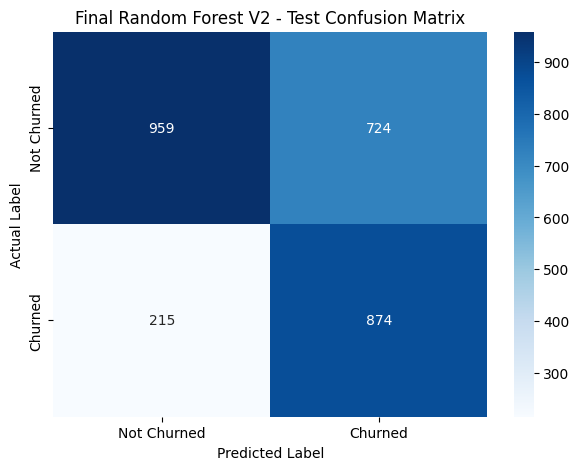

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Not Churned       0.82      0.57      0.67      1683
     Churned       0.55      0.80      0.65      1089

    accuracy                           0.66      2772
   macro avg       0.68      0.69      0.66      2772
weighted avg       0.71      0.66      0.66      2772

Actual Test Churn Rate: 0.3929
Predicted Test Churn Rate: 0.5765


In [48]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# --------------------------------
# 1. Set final classification threshold
# --------------------------------

FINAL_THRESHOLD = 0.36

# --------------------------------
# 2. Generate test probabilities
# --------------------------------

# Using the correct variable names for our best tuned model and test features
test_probabilities = best_rf.predict_proba(X_test_v2)[:, 1]

# Apply the selected threshold
test_predictions = (
    test_probabilities >= FINAL_THRESHOLD
).astype(int)

# --------------------------------
# 3. Calculate final metrics
# --------------------------------

final_results = {
    "Threshold": FINAL_THRESHOLD,
    "Accuracy": accuracy_score(y_test_v2, test_predictions),
    "Precision": precision_score(y_test_v2, test_predictions),
    "Recall": recall_score(y_test_v2, test_predictions),
    "F1 Score": f1_score(y_test_v2, test_predictions),
    "ROC-AUC": roc_auc_score(y_test_v2, test_probabilities),
    "PR-AUC": average_precision_score(y_test_v2, test_probabilities),
    "Balanced Accuracy": balanced_accuracy_score(
        y_test_v2, test_predictions
    )
}

final_results_df = pd.DataFrame(
    [final_results]
)

print("FINAL TEST PERFORMANCE")

display(final_results_df.round(4))

# --------------------------------
# 4. Confusion Matrix
# --------------------------------

cm = confusion_matrix(y_test_v2, test_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Churned", "Churned"],
    yticklabels=["Not Churned", "Churned"]
)

plt.title("Final Random Forest V2 - Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

# --------------------------------
# 5. Classification Report
# --------------------------------

print("CLASSIFICATION REPORT")

print(
    classification_report(
        y_test_v2,
        test_predictions,
        target_names=["Not Churned", "Churned"]
    )
)

# --------------------------------
# 6. Actual vs Predicted Churn Rate
# --------------------------------

print(
    "Actual Test Churn Rate:",
    round(y_test_v2.mean(), 4)
)

print(
    "Predicted Test Churn Rate:",
    round(test_predictions.mean(), 4)
)

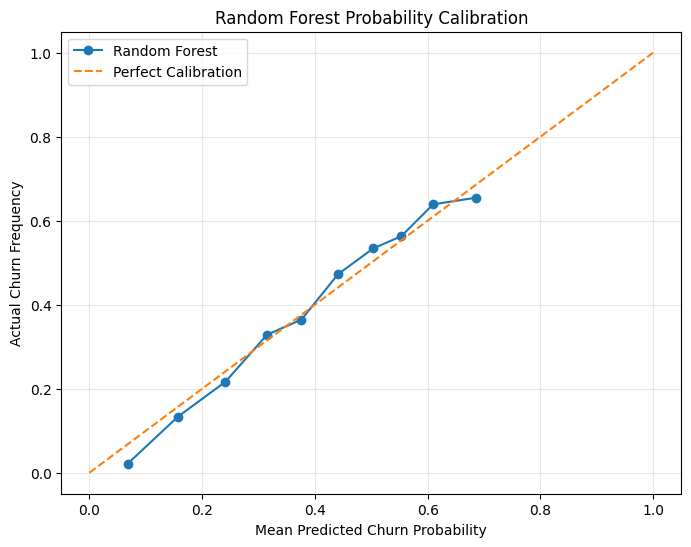

Brier Score: 0.1964


In [50]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# Calibration data
actual_fraction, predicted_fraction = calibration_curve(
    y_test_v2,
    test_probabilities,
    n_bins=10,
    strategy="quantile"
)

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    predicted_fraction,
    actual_fraction,
    marker="o",
    label="Random Forest"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Churn Probability")
plt.ylabel("Actual Churn Frequency")
plt.title("Random Forest Probability Calibration")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(
    "Brier Score:",
    round(brier_score_loss(y_test_v2, test_probabilities), 4)
)

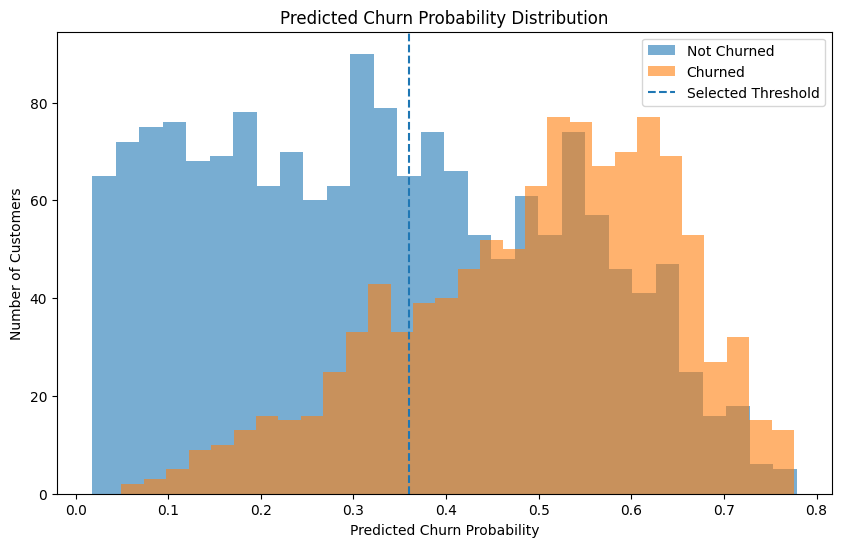

In [52]:
plt.figure(figsize=(10, 6))

plt.hist(
    test_probabilities[y_test_v2 == 0],
    bins=30,
    alpha=0.6,
    label="Not Churned"
)

plt.hist(
    test_probabilities[y_test_v2 == 1],
    bins=30,
    alpha=0.6,
    label="Churned"
)

plt.axvline(
    0.36,
    linestyle="--",
    label="Selected Threshold"
)

plt.xlabel("Predicted Churn Probability")
plt.ylabel("Number of Customers")
plt.title("Predicted Churn Probability Distribution")

plt.legend()
plt.show()

In [54]:
from sklearn.metrics import brier_score_loss

brier_score = brier_score_loss(
    y_test_v2,
    test_probabilities
)

print("Brier Score:", round(brier_score, 4))

Brier Score: 0.1964
